<a href="https://colab.research.google.com/github/khady92/ANALYSE-DE-DONNEES/blob/main/theme7_stats_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns

print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Seaborn :", sns.__version__)

NumPy : 2.4.6
Pandas : 2.2.3
Matplotlib : 3.10.0
Seaborn : 0.13.2


In [2]:
df = pd.DataFrame({
    "heures": [2, 5, 1, 8, 6, 3, 7, 4, 9, 5],
    "note":   [8, 12, 6, 16, 14, 9, 15, np.nan, 17, 11],
    "sexe":   ["F","M","F","F","M","M","F","M","F","M"],
    "groupe": ["A","B","A","B","A","B","A","B","A","B"],
})
df.head(10)

,heures,note,sexe,groupe
0,2,8.0,F,A
1,5,12.0,M,B
2,1,6.0,F,A
3,8,16.0,F,B
4,6,14.0,M,A
5,3,9.0,M,B
6,7,15.0,F,A
7,4,NaN,M,B
8,9,17.0,F,A
9,5,11.0,M,B


In [3]:
notes = df["note"].dropna().to_numpy()

print("Moyenne :", np.mean(notes))
print("Médiane :", np.median(notes))
print("Écart-type (ddof=0) :", np.std(notes))
print("Écart-type (ddof=1) :", np.std(notes, ddof=1))
print("Quartiles Q1, Q3 :", np.percentile(notes, [25, 75]))

Moyenne : 12.0
Médiane : 12.0
Écart-type (ddof=0) : 3.5901098714230026
Écart-type (ddof=1) : 3.8078865529319543
Quartiles Q1, Q3 : [ 9. 15.]


In [4]:
df.info()
print("-----")
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   heures  10 non-null     int64  
 1   note    9 non-null      float64
 2   sexe    10 non-null     object 
 3   groupe  10 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 452.0+ bytes
-----
heures      int64
note      float64
sexe       object
groupe     object
dtype: object


In [5]:
df.describe()

,heures,note
count,10.000000,9.000000
mean,5.000000,12.000000
std,2.581989,3.807887
min,1.000000,6.000000
25%,3.250000,9.000000
50%,5.000000,12.000000
75%,6.750000,15.000000
max,9.000000,17.000000


In [6]:
print(df["sexe"].value_counts())
print("-----")
print(df["groupe"].value_counts())

sexe
F    5
M    5
Name: count, dtype: int64
-----
groupe
A    5
B    5
Name: count, dtype: int64


In [7]:
print(df.isna().sum())
print("-----")
print("% manquant dans note :", df["note"].isna().mean() * 100)

heures    0
note      1
sexe      0
groupe    0
dtype: int64
-----
% manquant dans note : 10.0


In [8]:
df["note"] = df["note"].fillna(df["note"].median())
df["sexe"] = df["sexe"].astype("category")
df["groupe"] = df["groupe"].astype("category")

print(df.dtypes)
print("-----")
print(df["note"].describe())

heures       int64
note       float64
sexe      category
groupe    category
dtype: object
-----
count    10.00000
mean     12.00000
std       3.59011
min       6.00000
25%       9.50000
50%      12.00000
75%      14.75000
max      17.00000
Name: note, dtype: float64


In [9]:
print(df.groupby("groupe", observed=True)["note"].agg(["mean", "std"]))
print("-----")
print(pd.crosstab(df["sexe"], df["groupe"]))
print("-----")
print(df[["heures", "note"]].corr())

        mean       std
groupe                
A       12.0  4.743416
B       12.0  2.549510
-----
groupe  A  B
sexe        
F       4  1
M       1  4
-----
        heures    note
heures  1.0000  0.9829
note    0.9829  1.0000


In [11]:
df.to_csv("notes.csv", index=False)
df2 = pd.read_csv("notes.csv")
df2.head()

,heures,note,sexe,groupe
0,2,8.0,F,A
1,5,12.0,M,B
2,1,6.0,F,A
3,8,16.0,F,B
4,6,14.0,M,A


In [12]:
import matplotlib.pyplot as plt

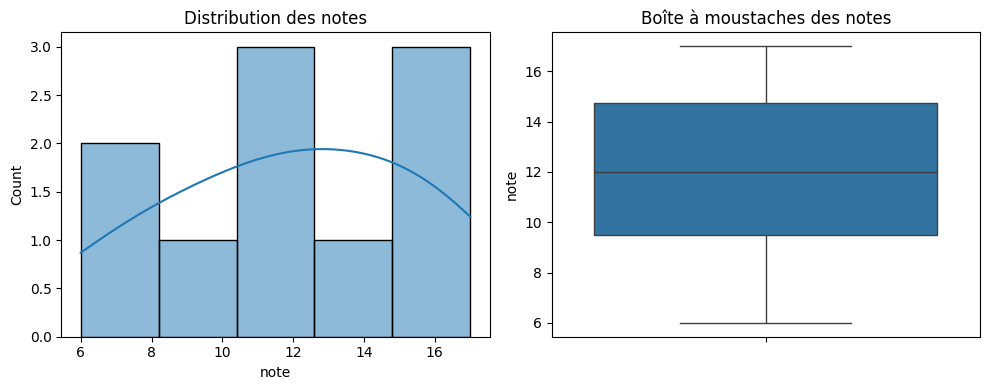

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df["note"], bins=5, kde=True, ax=ax[0])
ax[0].set_title("Distribution des notes")
sns.boxplot(y=df["note"], ax=ax[1])
ax[1].set_title("Boîte à moustaches des notes")
plt.tight_layout()
plt.show()

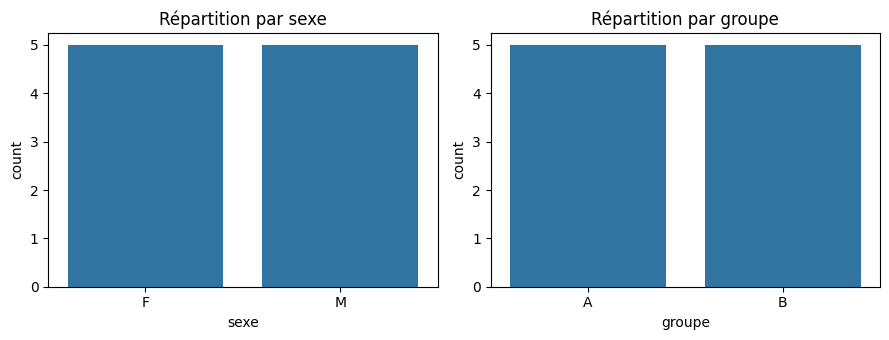

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
sns.countplot(x="sexe", data=df, ax=ax[0])
ax[0].set_title("Répartition par sexe")
sns.countplot(x="groupe", data=df, ax=ax[1])
ax[1].set_title("Répartition par groupe")
plt.tight_layout()
plt.show()

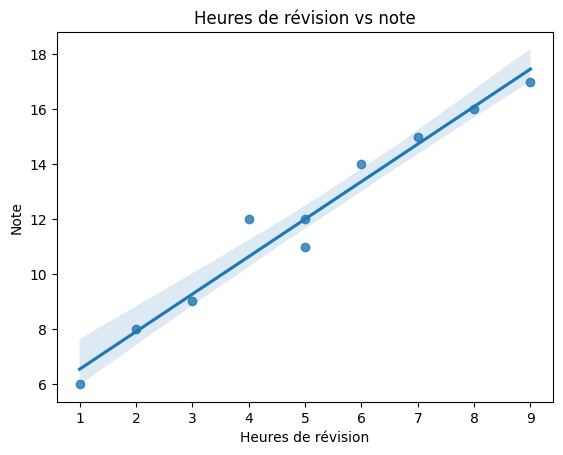

In [15]:
sns.regplot(x="heures", y="note", data=df)
plt.title("Heures de révision vs note")
plt.xlabel("Heures de révision")
plt.ylabel("Note")
plt.show()

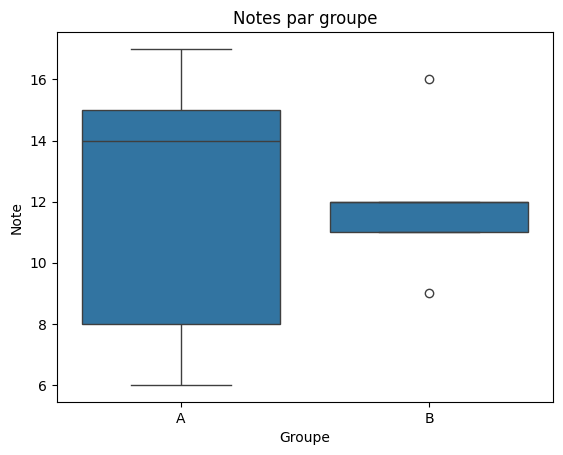

In [16]:
sns.boxplot(x="groupe", y="note", data=df)
plt.title("Notes par groupe")
plt.xlabel("Groupe")
plt.ylabel("Note")
plt.show()

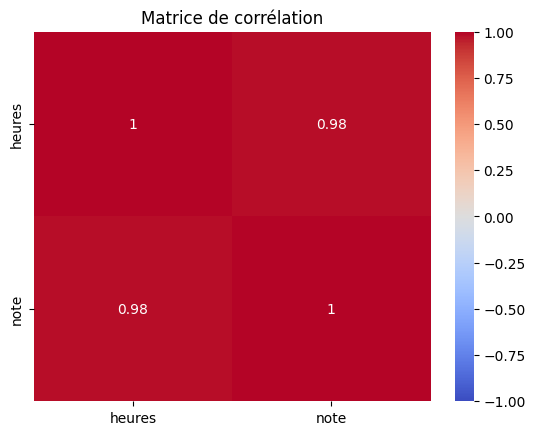

In [17]:
sns.heatmap(df[["heures", "note"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()